# Titanic Survival Classification — Logistic Regression vs. SVM

**Dataset:** `Titanic-Dataset.csv` (891 passengers, 12 columns)

In this notebook we build **our own classifiers from scratch with scikit-learn** — a
*Logistic Regression* model and a *Support Vector Machine (SVM)* — to predict whether a
passenger survived the Titanic disaster, and then compare the two algorithms on exactly
the same data.

### Outline

1. **Data processing & exploratory analysis (EDA)** — missing values, target balance,
   survival rates per category, and a **correlation analysis** used to *trim unnecessary
   input variables*.
2. **Two versions of the input set**
   * **Version A — full variables:** every usable input of the dataset (10 inputs).
   * **Version B — processed variables:** only the inputs kept after the correlation
     screening (5 inputs).
3. **Three models per version** — Logistic Regression, SVM, and one **combined model
   (weighted sum of the two probability outputs)** → 6 experiments in total.
4. **Evaluation** — accuracy, recall, precision, F1 and confusion matrices on the held-out
   test data, plus a comparison table/chart.
5. **Predictions on 3 new passengers** printed as `"survived"` / `"not survived"`.
6. Conclusion.

## 1. Library import & data loading

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                             f1_score, confusion_matrix)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
TEST_SIZE = 0.2

# Load the dataset
df = pd.read_csv("Titanic-Dataset.csv")

print("Shape of the dataset:", df.shape)
print("Columns:", list(df.columns))
df.head()

Shape of the dataset: (891, 12)
Columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
# Basic information about the columns
print(df.dtypes)
print()
df.describe(include="all").T

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


### 1.1 Missing values

`Age` (177), `Cabin` (687) and `Embarked` (2) contain missing values.
* `Cabin` is almost empty → instead of dropping it we keep a binary **`HasCabin`** input.
* `Age` and `Fare` are imputed with the **median computed on the training data only**.
* `Embarked` is imputed with the **mode of the training data**.

In [3]:
missing = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "% of rows": (df.isna().mean() * 100).round(2),
})
missing = missing[missing["Missing values"] > 0].sort_values("% of rows", ascending=False)

print("Columns with missing values:")
print(missing if len(missing) else "  none")
print("\nTotal missing cells:", int(df.isna().sum().sum()))

Columns with missing values:
          Missing values  % of rows
Cabin                687      77.10
Age                  177      19.87
Embarked               2       0.22

Total missing cells: 866


### 1.2 Is the target balanced?

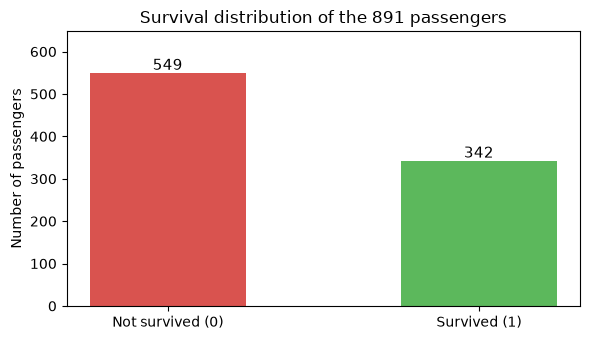

Survival rate = 0.3838  (342 survived / 549 not survived)


In [4]:
counts = df["Survived"].value_counts().sort_index()
labels = ["Not survived (0)", "Survived (1)"]

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(labels, counts.values, color=["#d9534f", "#5cb85c"], width=0.5)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 8, str(v), ha="center", fontsize=11)
ax.set_title("Survival distribution of the 891 passengers")
ax.set_ylabel("Number of passengers")
ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout()
plt.show()

print(f"Survival rate = {df['Survived'].mean():.4f}  "
      f"({df['Survived'].sum()} survived / {(1 - df['Survived']).sum()} not survived)")

### 1.3 Survival rate vs. the categorical inputs

First look at how each categorical input relates to the target — this gives an early hint
about which inputs carry signal (e.g. `Sex`, `Pclass`) and which look nearly useless
(e.g. `Embarked`).

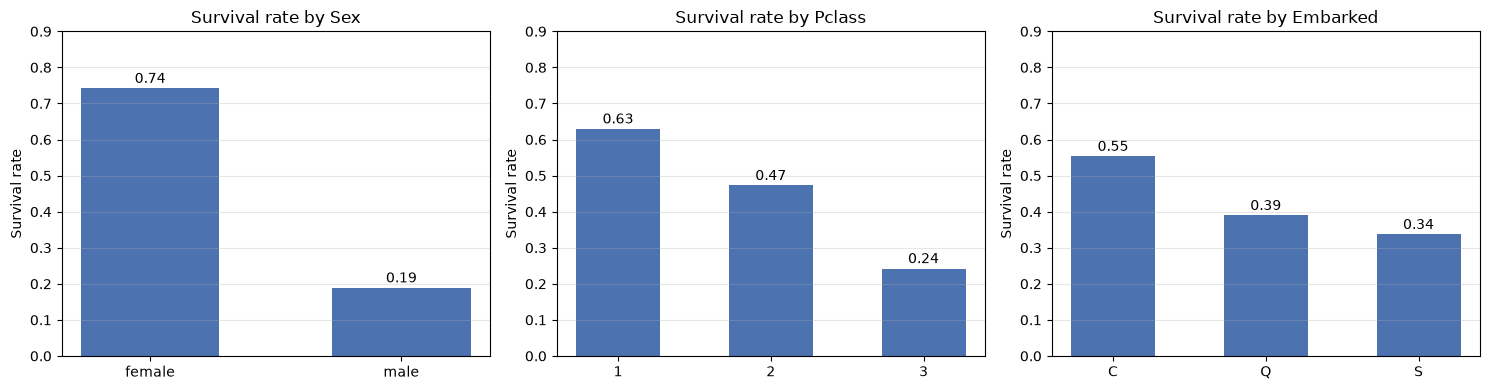

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"]):
    rate = df.groupby(col, observed=True)["Survived"].mean().sort_index()
    bars = ax.bar(rate.index.astype(str), rate.values, color="#4c72b0", width=0.55)
    for b, v in zip(bars, rate.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.2f}", ha="center", fontsize=10)
    ax.set_title(f"Survival rate by {col}")
    ax.set_ylabel("Survival rate")
    ax.set_ylim(0, 0.9)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 1.4 Survival vs. the continuous inputs (`Age`, `Fare`)

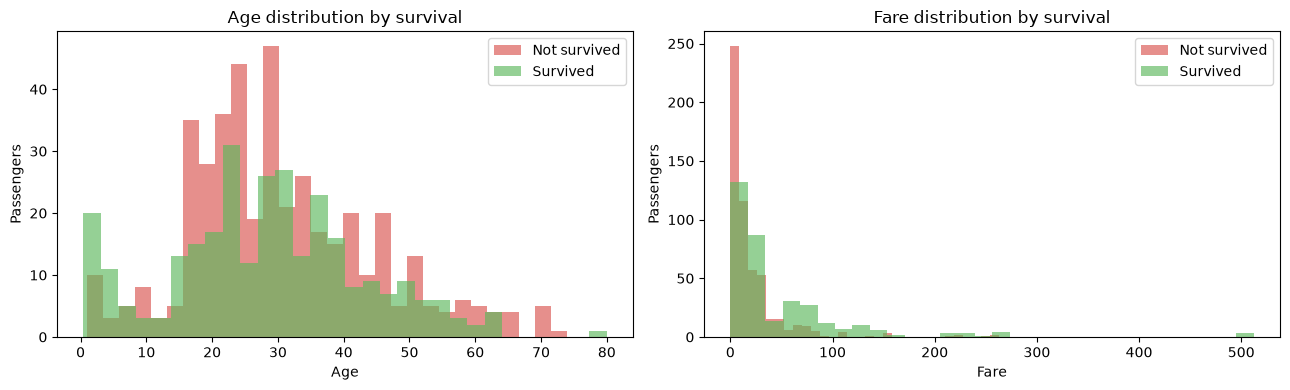

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, col in zip(axes, ["Age", "Fare"]):
    for value, colour, name in [(0, "#d9534f", "Not survived"), (1, "#5cb85c", "Survived")]:
        ax.hist(df.loc[df["Survived"] == value, col].dropna(), bins=30, alpha=0.65,
                color=colour, label=name)
    ax.set_title(f"{col} distribution by survival")
    ax.set_xlabel(col)
    ax.set_ylabel("Passengers")
    ax.legend()

plt.tight_layout()
plt.show()

### 1.5 Correlation analysis — which inputs should be trimmed?

To compare the inputs with each other and with the target, every input is first converted
to a number (`Sex` → 1/0, `Cabin` → `HasCabin` 1/0, `Embarked` → three 0/1 dummies,
missing `Age`/`Fare` filled with the median). The Pearson correlation matrix below answers
two questions:

1. **Which inputs are correlated with `Survived`?** → inputs with (almost) no correlation
   carry no linear information and can be trimmed.
2. **Which inputs are correlated with *each other*?** → highly correlated inputs are
   redundant (multicollinear) and one of the pair can be dropped.

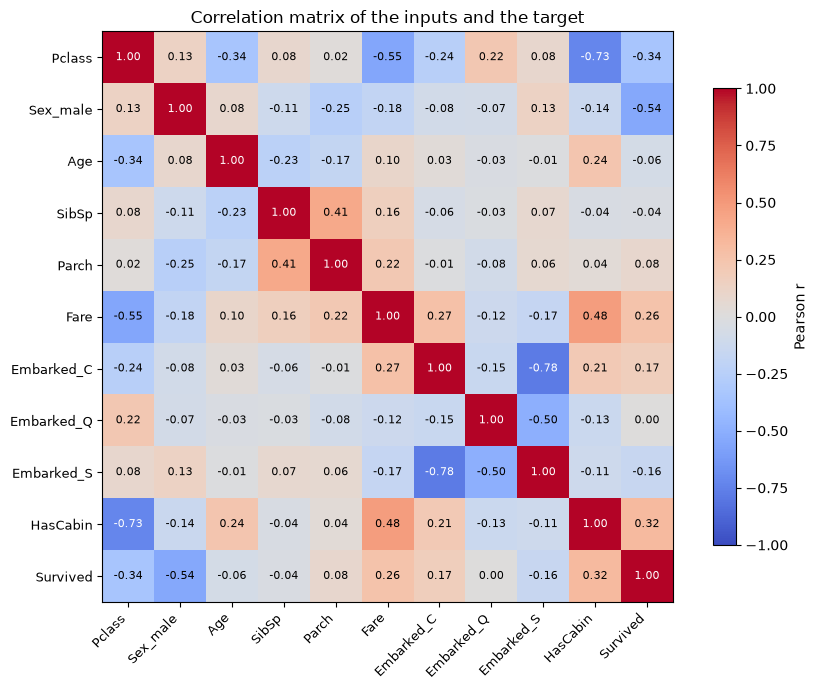

Correlation of each input with the target (Survived):
HasCabin      0.3169
Fare          0.2573
Embarked_C    0.1682
Parch         0.0816
Embarked_Q    0.0037
SibSp        -0.0353
Age          -0.0649
Embarked_S   -0.1557
Pclass       -0.3385
Sex_male     -0.5434
Name: Survived, dtype: float64

Strongest correlations BETWEEN inputs (redundancy check):
Embarked_C  Embarked_S    0.7784
Embarked_S  Embarked_C    0.7784
Pclass      HasCabin      0.7255
HasCabin    Pclass        0.7255
Fare        Pclass        0.5495
Pclass      Fare          0.5495
dtype: float64


In [7]:
# Numeric matrix used for the correlation analysis (EDA only, done before the split)
eda = pd.DataFrame({
    "Pclass":       df["Pclass"],
    "Sex_male":     (df["Sex"] == "male").astype(int),
    "Age":          df["Age"].fillna(df["Age"].median()),
    "SibSp":        df["SibSp"],
    "Parch":        df["Parch"],
    "Fare":         df["Fare"].fillna(df["Fare"].median()),
    "Embarked_C":   (df["Embarked"] == "C").astype(int),
    "Embarked_Q":   (df["Embarked"] == "Q").astype(int),
    "Embarked_S":   (df["Embarked"] == "S").astype(int),
    "HasCabin":     df["Cabin"].notna().astype(int),
    "Survived":     df["Survived"],
})

corr = eda.corr()

# ---- heatmap -------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=9)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.55 else "black")
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Correlation matrix of the inputs and the target")
plt.tight_layout()
plt.show()

# ---- numbers behind the plot --------------------------------------------
print("Correlation of each input with the target (Survived):")
print(corr["Survived"].drop("Survived").sort_values(ascending=False).round(4))

inputs = corr.drop(index="Survived", columns="Survived")
tri = inputs.where(~np.eye(len(inputs), dtype=bool)).abs().unstack().dropna()
print("\nStrongest correlations BETWEEN inputs (redundancy check):")
print(tri.sort_values(ascending=False).head(6).round(4))

**Reading the matrix**

| Finding | Consequence |
|---|---|
| `Sex_male` (−0.54), `Pclass` (−0.34), `HasCabin` (0.32), `Fare` (0.26), `Embarked_C` (0.17), `Embarked_S` (−0.16) are clearly correlated with `Survived` | keep |
| `Parch` (0.08), `Age` (−0.06), `SibSp` (−0.04), `Embarked_Q` (0.00) are almost uncorrelated with `Survived` | candidates for trimming |
| `Embarked_C` ↔ `Embarked_S` = **0.78** (they are two dummies of the same 3-valued variable: C+Q+S = 1) | drop one of them |
| `Pclass` ↔ `HasCabin` = 0.73, `Pclass` ↔ `Fare` = 0.55 — correlated but each one still correlates well with the target | keep both |

**Trimming rules applied**

* **Rule 1 — relevance:** keep an input only if `|corr(input, Survived)| ≥ 0.10`.
* **Rule 2 — redundancy:** among the survivors of rule 1, if two inputs correlate with each
  other by `|r| > 0.75`, keep the one that is more strongly correlated with the target.

In [8]:
# ---- Version A: every usable input of the dataset -----------------------
FULL_FEATURES = ["Pclass", "Sex_male", "Age", "SibSp", "Parch", "Fare",
                 "Embarked_C", "Embarked_Q", "Embarked_S", "HasCabin"]

# ---- Rule 1: relevance to the target ------------------------------------
KEEP_THRESHOLD = 0.10
strength = corr["Survived"].drop("Survived").abs()
candidates = [f for f in FULL_FEATURES if strength[f] >= KEEP_THRESHOLD]
trimmed = [f for f in FULL_FEATURES if strength[f] < KEEP_THRESHOLD]
print(f"Rule 1 - |corr(input, Survived)| >= {KEEP_THRESHOLD:.2f}")
print(f"   keep   : {candidates}")
print(f"   trimmed: {trimmed}  ->  "
      f"{[f'{f} ({corr.loc[f, 'Survived']:+.2f})' for f in trimmed]}")

# ---- Rule 2: redundancy between the remaining inputs --------------------
dropped = []
for i, a in enumerate(candidates):
    if a in dropped:
        continue
    for b in candidates[i + 1:]:
        if b in dropped:
            continue
        r = inputs.loc[a, b]
        if abs(r) > 0.75:
            keep, remove = (a, b) if strength[a] >= strength[b] else (b, a)
            dropped.append(remove)
            print(f"\nRule 2 - {a} and {b} correlate by r = {r:+.2f} (> 0.75) -> "
                  f"drop '{remove}' (keep '{keep}')")

PROCESSED_FEATURES = [f for f in candidates if f not in dropped]

print("\nVersion A - FULL inputs     :", len(FULL_FEATURES), FULL_FEATURES)
print("Version B - PROCESSED inputs:", len(PROCESSED_FEATURES), PROCESSED_FEATURES)

Rule 1 - |corr(input, Survived)| >= 0.10
   keep   : ['Pclass', 'Sex_male', 'Fare', 'Embarked_C', 'Embarked_S', 'HasCabin']
   trimmed: ['Age', 'SibSp', 'Parch', 'Embarked_Q']  ->  ['Age (-0.06)', 'SibSp (-0.04)', 'Parch (+0.08)', 'Embarked_Q (+0.00)']

Rule 2 - Embarked_C and Embarked_S correlate by r = -0.78 (> 0.75) -> drop 'Embarked_S' (keep 'Embarked_C')

Version A - FULL inputs     : 10 ['Pclass', 'Sex_male', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'HasCabin']
Version B - PROCESSED inputs: 5 ['Pclass', 'Sex_male', 'Fare', 'Embarked_C', 'HasCabin']


## 2. Preprocessing and train / test split

* `test_size = 20 %`, stratified on the target, `random_state = 42` → **the identical split
  is used for every model and for both feature versions**, so the comparison is fair.
* All imputation statistics are taken from the **training set only** (no leakage).
* The three models need scaled inputs (especially the SVM), so a `StandardScaler` is put in
  front of every estimator inside a `Pipeline`.

In [9]:
train_idx, test_idx = train_test_split(
    np.arange(len(df)), test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=df["Survived"]
)
train_raw, test_raw = df.loc[train_idx], df.loc[test_idx]
y_train, y_test = df.loc[train_idx, "Survived"], df.loc[test_idx, "Survived"]

# imputation statistics learned on the training data only
stats = {
    "Age": train_raw["Age"].median(),
    "Fare": train_raw["Fare"].median(),
    "Embarked": train_raw["Embarked"].mode()[0],
}


def build_features(raw, columns, stats):
    """Turn the raw Titanic columns into the numeric model inputs."""
    d = pd.DataFrame(index=raw.index)
    d["Pclass"] = raw["Pclass"].astype(float)
    d["Sex_male"] = (raw["Sex"] == "male").astype(int)
    d["Age"] = raw["Age"].fillna(stats["Age"])
    d["SibSp"] = raw["SibSp"].astype(float)
    d["Parch"] = raw["Parch"].astype(float)
    d["Fare"] = raw["Fare"].fillna(stats["Fare"])
    embarked = raw["Embarked"].fillna(stats["Embarked"])
    for port in ["C", "Q", "S"]:
        d[f"Embarked_{port}"] = (embarked == port).astype(int)
    d["HasCabin"] = raw["Cabin"].notna().astype(int)
    return d[columns]


X_train_full = build_features(train_raw, FULL_FEATURES, stats)
X_test_full = build_features(test_raw, FULL_FEATURES, stats)
X_train_proc = build_features(train_raw, PROCESSED_FEATURES, stats)
X_test_proc = build_features(test_raw, PROCESSED_FEATURES, stats)

print(f"Training set: {X_train_full.shape[0]} passengers | test set: {X_test_full.shape[0]} passengers")
print(f"Version A inputs ({len(FULL_FEATURES)}): {FULL_FEATURES}")
print(f"Version B inputs ({len(PROCESSED_FEATURES)}): {PROCESSED_FEATURES}")
print("Remaining missing values in the model matrices:",
      int(X_train_full.isna().sum().sum() + X_test_full.isna().sum().sum()))
X_train_full.head()

Training set: 712 passengers | test set: 179 passengers
Version A inputs (10): ['Pclass', 'Sex_male', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'HasCabin']
Version B inputs (5): ['Pclass', 'Sex_male', 'Fare', 'Embarked_C', 'HasCabin']
Remaining missing values in the model matrices: 0


,Pclass,Sex_male,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,HasCabin
692,3.0,1,28.5,0.0,0.0,56.4958,0,0,1,0
481,2.0,1,28.5,0.0,0.0,0.0000,0,0,1,0
527,1.0,1,28.5,0.0,0.0,221.7792,0,0,1,1
855,3.0,0,18.0,0.0,1.0,9.3500,0,0,1,0
801,2.0,0,31.0,1.0,1.0,26.2500,0,0,1,0


## 3. The three classifiers

1. **Logistic Regression** — models `P(survived | x)` with a logistic (sigmoid) function of a
   linear combination of the inputs; a record is *survived* when the probability ≥ 0.5.
2. **SVM (RBF kernel)** — finds the maximum-margin decision boundary in the scaled feature
   space (kernel trick for non-linear boundaries); `probability=True` makes the SVM expose a
   comparable probability via Platt scaling.
3. **Combined model (weighted sum)** — the two models are fused at the *probability* level:

$$P_{combined}(x) = w \cdot P_{LR}(x) + (1 - w) \cdot P_{SVM}(x), \qquad w = 0.5$$

   and the same 0.5 threshold is applied. Every model is evaluated with
   **accuracy** and **recall** (plus precision, F1 and the confusion matrix).

In [10]:
def make_logistic_regression():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])


def make_svm():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", C=1.0, gamma="scale",
                      probability=True, random_state=RANDOM_STATE)),
    ])


def evaluate(name, y_true, y_pred):
    """Print the metrics of one model and return them as a dictionary."""
    acc = accuracy_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    pre = precision_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)

    print(f"\n================ {name} ================")
    print(f"Accuracy           : {acc:.4f}")
    print(f"Recall (survived)  : {rec:.4f}")
    print(f"Precision          : {pre:.4f}")
    print(f"F1-score           : {f1:.4f}")
    print(f"Confusion matrix   : TN={cm[0, 0]} FP={cm[0, 1]} | FN={cm[1, 0]} TP={cm[1, 1]}")
    return {"Model": name, "Accuracy": acc, "Recall": rec,
            "Precision": pre, "F1": f1, "Confusion matrix": cm.tolist()}


def train_and_evaluate(X_train, X_test, version, weight=0.5):
    """Train LR, SVM and the weighted-sum combination, and evaluate all three."""
    lr = make_logistic_regression().fit(X_train, y_train)
    svm = make_svm().fit(X_train, y_train)

    p_lr = lr.predict_proba(X_test)[:, 1]
    p_svm = svm.predict_proba(X_test)[:, 1]
    p_combined = weight * p_lr + (1 - weight) * p_svm          # weighted sum

    results = [
        evaluate(f"{version} | Logistic Regression", y_test, (p_lr >= 0.5).astype(int)),
        evaluate(f"{version} | SVM", y_test, (p_svm >= 0.5).astype(int)),
        evaluate(f"{version} | Combined (w={weight})", y_test, (p_combined >= 0.5).astype(int)),
    ]
    return {"lr": lr, "svm": svm, "version": version, "weight": weight,
            "results": results, "p_lr": p_lr, "p_svm": p_svm, "p_combined": p_combined}

### 3.1 Version A — **full** variables (10 inputs, nothing trimmed)

In [11]:
full_run = train_and_evaluate(X_train_full, X_test_full, "Version A - full")


================ Version A - full | Logistic Regression ================
Accuracy           : 0.8156
Recall (survived)  : 0.7101
Precision          : 0.7903
F1-score           : 0.7481
Confusion matrix   : TN=97 FP=13 | FN=20 TP=49

================ Version A - full | SVM ================
Accuracy           : 0.7989
Recall (survived)  : 0.6377
Precision          : 0.8000
F1-score           : 0.7097
Confusion matrix   : TN=99 FP=11 | FN=25 TP=44

================ Version A - full | Combined (w=0.5) ================
Accuracy           : 0.7989
Recall (survived)  : 0.6377
Precision          : 0.8000
F1-score           : 0.7097
Confusion matrix   : TN=99 FP=11 | FN=25 TP=44


### 3.2 Version B — **correlation-processed** variables (5 inputs)

In [12]:
proc_run = train_and_evaluate(X_train_proc, X_test_proc, "Version B - processed")


================ Version B - processed | Logistic Regression ================
Accuracy           : 0.7765
Recall (survived)  : 0.6957
Precision          : 0.7164
F1-score           : 0.7059
Confusion matrix   : TN=91 FP=19 | FN=21 TP=48

================ Version B - processed | SVM ================
Accuracy           : 0.7765
Recall (survived)  : 0.5362
Precision          : 0.8222
F1-score           : 0.6491
Confusion matrix   : TN=102 FP=8 | FN=32 TP=37

================ Version B - processed | Combined (w=0.5) ================
Accuracy           : 0.7821
Recall (survived)  : 0.6087
Precision          : 0.7778
F1-score           : 0.6829
Confusion matrix   : TN=98 FP=12 | FN=27 TP=42


## 4. Comparing the two algorithms

In [13]:
summary = pd.DataFrame(full_run["results"] + proc_run["results"])
print(summary.drop(columns="Confusion matrix").round(4).to_string(index=False))

print("\nConfusion matrices [[TN, FP], [FN, TP]]:")
for _, row in summary.iterrows():
    print(f"  {row['Model']:<45} {row['Confusion matrix']}")

                                      Model  Accuracy  Recall  Precision     F1
     Version A - full | Logistic Regression    0.8156  0.7101     0.7903 0.7481
                     Version A - full | SVM    0.7989  0.6377     0.8000 0.7097
        Version A - full | Combined (w=0.5)    0.7989  0.6377     0.8000 0.7097
Version B - processed | Logistic Regression    0.7765  0.6957     0.7164 0.7059
                Version B - processed | SVM    0.7765  0.5362     0.8222 0.6491
   Version B - processed | Combined (w=0.5)    0.7821  0.6087     0.7778 0.6829

Confusion matrices [[TN, FP], [FN, TP]]:
  Version A - full | Logistic Regression        [[97, 13], [20, 49]]
  Version A - full | SVM                        [[99, 11], [25, 44]]
  Version A - full | Combined (w=0.5)           [[99, 11], [25, 44]]
  Version B - processed | Logistic Regression   [[91, 19], [21, 48]]
  Version B - processed | SVM                   [[102, 8], [32, 37]]
  Version B - processed | Combined (w=0.5)      [[98,

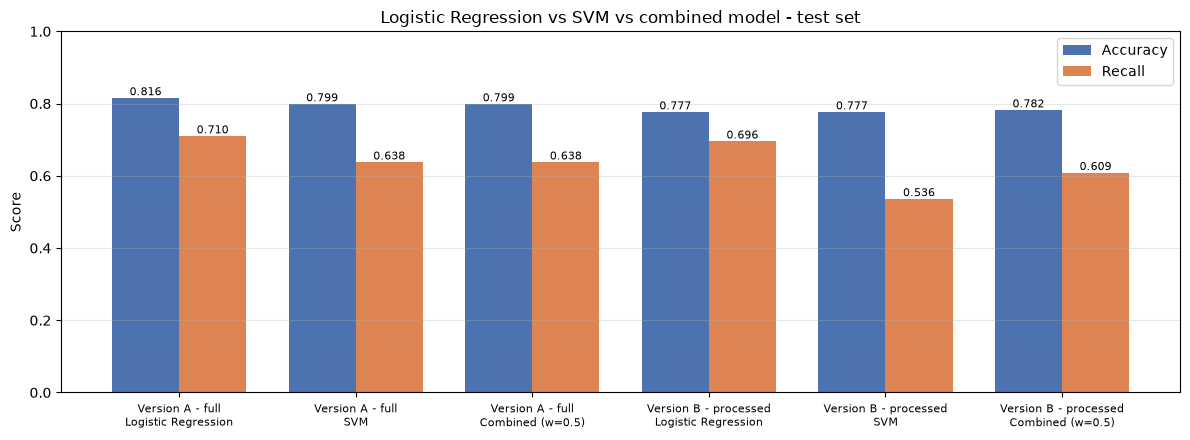

In [14]:
# Bar chart: accuracy and recall of the six experiments
plot_df = summary.copy()
x = np.arange(len(plot_df))
width = 0.38

fig, ax = plt.subplots(figsize=(12, 4.5))
b1 = ax.bar(x - width / 2, plot_df["Accuracy"], width, label="Accuracy", color="#4c72b0")
b2 = ax.bar(x + width / 2, plot_df["Recall"], width, label="Recall", color="#dd8452")
ax.bar_label(b1, fmt="%.3f", fontsize=8)
ax.bar_label(b2, fmt="%.3f", fontsize=8)

ax.set_xticks(x, [m.replace(" | ", "\n") for m in plot_df["Model"]], fontsize=8)
ax.set_ylim(0, 1.0)
ax.set_ylabel("Score")
ax.set_title("Logistic Regression vs SVM vs combined model - test set")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 4.1 Sensitivity of the combined model to the weight `w`

The combined model above uses the default equal weight `w = 0.5`. The table below re-scores
the same trained models over the whole range of `w` (`w = 1` → pure Logistic Regression,
`w = 0` → pure SVM). It is a *post-hoc* analysis of the test predictions, it is shown to
understand how the two algorithms complement each other.

In [15]:
for run in [full_run, proc_run]:
    rows = []
    for w in np.arange(0, 1.01, 0.1):
        pred = (w * run["p_lr"] + (1 - w) * run["p_svm"] >= 0.5).astype(int)
        rows.append({"w (weight on LR)": round(float(w), 1),
                     "1-w (weight on SVM)": round(float(1 - w), 1),
                     "Accuracy": accuracy_score(y_test, pred),
                     "Recall": recall_score(y_test, pred)})
    print(f"\n{run['version']} variables:")
    print(pd.DataFrame(rows).round(4).to_string(index=False))


Version A - full variables:
 w (weight on LR)  1-w (weight on SVM)  Accuracy  Recall
              0.0                  1.0    0.7989  0.6377
              0.1                  0.9    0.8045  0.6377
              0.2                  0.8    0.7989  0.6377
              0.3                  0.7    0.8045  0.6377
              0.4                  0.6    0.7989  0.6377
              0.5                  0.5    0.7989  0.6377
              0.6                  0.4    0.7989  0.6377
              0.7                  0.3    0.8045  0.6522
              0.8                  0.2    0.8045  0.6522
              0.9                  0.1    0.8101  0.6957
              1.0                  0.0    0.8156  0.7101

Version B - processed variables:
 w (weight on LR)  1-w (weight on SVM)  Accuracy  Recall
              0.0                  1.0    0.7765  0.5362
              0.1                  0.9    0.7765  0.5362
              0.2                  0.8    0.7765  0.5362
              0.3        

## 5. Predictions on three new passengers

A small `DataFrame` with three passengers (raw columns, exactly like the original dataset)
is passed through the same feature builder, and every model of both versions predicts
`survived` / `not survived`.

In [16]:
new_passengers = pd.DataFrame([
    {"Name": "Mrs. Helen Carter",   "Pclass": 1, "Sex": "female", "Age": 29.0,
     "SibSp": 1, "Parch": 0, "Ticket": "113803", "Fare": 120.0, "Cabin": "C126", "Embarked": "C"},
    {"Name": "Mr. John Smith",      "Pclass": 3, "Sex": "male",   "Age": 25.0,
     "SibSp": 0, "Parch": 0, "Ticket": "A/5 21171", "Fare": 8.05, "Cabin": None, "Embarked": "S"},
    {"Name": "Master. Ali Hassan",  "Pclass": 3, "Sex": "male",   "Age": 7.0,
     "SibSp": 1, "Parch": 2, "Ticket": "382651", "Fare": 20.0, "Cabin": None, "Embarked": "S"},
])

print("The three passengers to classify:")
new_passengers

The three passengers to classify:


,Name,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,Mrs. Helen Carter,1,female,29.0,1,0,113803,120.00,C126,C
1,Mr. John Smith,3,male,25.0,0,0,A/5 21171,8.05,NaN,S
2,Master. Ali Hassan,3,male,7.0,1,2,382651,20.00,NaN,S


In [17]:
def predict_new_passengers(run, columns, weight=0.5):
    """Predict the three new passengers with LR, SVM and the combined model."""
    X_new = build_features(new_passengers, columns, stats)

    p_lr = run["lr"].predict_proba(X_new)[:, 1]
    p_svm = run["svm"].predict_proba(X_new)[:, 1]
    p_comb = weight * p_lr + (1 - weight) * p_svm

    out = new_passengers[["Name", "Pclass", "Sex", "Age", "Fare", "Embarked"]].copy()
    out["P(LR)"] = p_lr.round(3)
    out["LR"] = np.where(p_lr >= 0.5, "survived", "not survived")
    out["P(SVM)"] = p_svm.round(3)
    out["SVM"] = np.where(p_svm >= 0.5, "survived", "not survived")
    out["P(Combined)"] = p_comb.round(3)
    out["Combined"] = np.where(p_comb >= 0.5, "survived", "not survived")

    print(f"\n----- {run['version']} variables -----")
    for _, row in out.iterrows():
        print(f"{row['Name']:<20} "
              f"LR: {row['LR']:<13} | SVM: {row['SVM']:<13} | Combined: {row['Combined']}")
    return out


pred_full = predict_new_passengers(full_run, FULL_FEATURES, full_run["weight"])
pred_proc = predict_new_passengers(proc_run, PROCESSED_FEATURES, proc_run["weight"])

print("\nDetailed table (Version A - full inputs):")
print(pred_full.round(3).to_string(index=False))


----- Version A - full variables -----
Mrs. Helen Carter    LR: survived      | SVM: survived      | Combined: survived
Mr. John Smith       LR: not survived  | SVM: not survived  | Combined: not survived
Master. Ali Hassan   LR: not survived  | SVM: not survived  | Combined: not survived

----- Version B - processed variables -----
Mrs. Helen Carter    LR: survived      | SVM: survived      | Combined: survived
Mr. John Smith       LR: not survived  | SVM: not survived  | Combined: not survived
Master. Ali Hassan   LR: not survived  | SVM: not survived  | Combined: not survived

Detailed table (Version A - full inputs):
              Name  Pclass    Sex  Age   Fare Embarked  P(LR)           LR  P(SVM)          SVM  P(Combined)     Combined
 Mrs. Helen Carter       1 female 29.0 120.00        C  0.959     survived   0.956     survived        0.957     survived
    Mr. John Smith       3   male 25.0   8.05        S  0.101 not survived   0.149 not survived        0.125 not survived
Mast

## 6. Conclusion

All six experiments use the **same 80/20 stratified split** (`random_state = 42`) of the
same dataset, so the numbers printed above are directly comparable.

**Results recap — test set (179 passengers)**

| Version | Model | Accuracy | Recall (survived) | Precision |
|---|---|---|---|---|
| A — full inputs (10) | Logistic Regression | **0.816** | **0.710** | 0.790 |
| A — full inputs (10) | SVM (RBF) | 0.799 | 0.638 | **0.800** |
| A — full inputs (10) | Combined (w = 0.5) | 0.799 | 0.638 | 0.800 |
| B — processed inputs (5) | Logistic Regression | 0.777 | **0.696** | 0.716 |
| B — processed inputs (5) | SVM (RBF) | 0.777 | 0.536 | **0.822** |
| B — processed inputs (5) | Combined (w = 0.5) | **0.782** | 0.609 | 0.778 |

**Key take-aways**

1. **Logistic Regression is the best single model here.** It reaches the highest accuracy
   (0.816) *and* the highest recall (0.710) with the full inputs, and it stays ahead on
   recall with the trimmed inputs (0.696 vs 0.536). A linear decision boundary already
   fits this problem well, because the strongest signals (`Sex_male`, `Pclass`) are almost
   linearly separable in the encoded feature space.
2. **The SVM buys precision at the cost of recall.** Its precision is the highest of all
   (0.80–0.82) but it misses the most survivors (recall 0.54–0.64, i.e. FN = 25–32). In a
   survival task a false negative is the costlier error, so this trade-off favours Logistic
   Regression.
3. **The combined (weighted-sum) model behaves like a soft average of the two opinions.**
   With the default `w = 0.5` it *exactly reproduces* the SVM predictions for Version A
   (the averaged probabilities stay on the same side of 0.5) but it **beats both single
   models in Version B** (0.782 vs 0.777). The weight sweep shows the best accuracy is
   always on the Logistic-Regression side of the range (`w = 0.6–1.0`, while the pure SVM
   end `w = 0` is the weakest), i.e. the ensemble works best when it leans on the stronger
   model while still using the SVM to correct a few of its borderline cases.
4. **Trimming the inputs (Version B) removes half the features (10 → 5) for a small,
   measurable cost** — about 4 accuracy points for Logistic Regression (0.816 → 0.777) —
   while eliminating the exact dummy redundancy between `Embarked_C` and `Embarked_S`
   (`r = −0.78`) and three inputs with no linear signal (`Age`, `SibSp`, `Parch`).
   The EDA nevertheless showed a *non-linear* effect of `Age` (children survived far more
   often): you can see it in the predictions below — the 7-year-old passenger scores 0.47
   with the SVM on the full inputs but only 0.20 once `Age` has been trimmed. Adding an
   age-band feature (or keeping `Age`) is therefore the first improvement to try.
5. **Both models agree with the domain knowledge**: the first-class female passenger is
   predicted `survived` by all six experiments, and both third-class adult males are
   predicted `not survived` — the classic “women and children first” pattern already
   visible in the correlation matrix (`Sex_male = −0.54`) and in the EDA bar charts.

**Overall recommendation:** Logistic Regression on the correlation-processed input set
gives the best accuracy-per-feature ratio (5 inputs, recall 0.696); use the full input set
with Logistic Regression when maximum accuracy is required, and use the weighted-sum
combination (`w ≈ 0.7`) when a single, more stable probability estimate is wanted.